In [23]:
import pandas as pd
import numpy as np
import os
from datetime import date
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
FOLDER = "../data/processed"

In [25]:
agg_crowding_df = pd.read_parquet(os.path.join(FOLDER, "agg_base_crowding.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))]) 
core_df = pd.read_parquet(os.path.join(FOLDER, "core_base.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))]) 
core_summary_df = pd.read_parquet(os.path.join(FOLDER, "core_summary_base.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))]) 
fund_df = pd.read_parquet(os.path.join(FOLDER, "fund_base.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))]) 
network_df = pd.read_parquet(os.path.join(FOLDER, "network_monthly_base.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))])
panel_df = pd.read_parquet(os.path.join(FOLDER, "panel_base.parquet"),\
    filters=[("month_end", ">=", date(2012, 12, 31))])

In [26]:
type = "base"

# Data Analysis

In [27]:
network_df.head()

,month_end,n_stocks,n_funds,n_positions,n_stocks_linked,giant_size,giant_share,giant_density,median_shared,max_shared,n_communities,n_cores,stocks_in_cores,share_in_cores,largest_core_size,largest_core_density,largest_core_coassign,share_cores_hub_led
0,2012-12-31,138,86,235,20,5,0.036232,0.500000,2.0,2,5,4,18,0.130435,5,0.500000,1.0,1.0
1,2013-01-31,133,89,239,23,14,0.105263,0.153846,2.0,2,6,4,19,0.142857,6,0.333333,1.0,1.0
2,2013-02-28,128,92,236,23,10,0.078125,0.222222,2.0,2,7,3,15,0.117188,5,0.500000,1.0,1.0
3,2013-03-31,135,91,244,21,11,0.081481,0.218182,2.0,2,5,3,17,0.125926,6,0.533333,1.0,1.0
4,2013-04-30,144,95,258,23,19,0.131944,0.134503,2.0,4,6,4,19,0.131944,5,0.500000,1.0,1.0


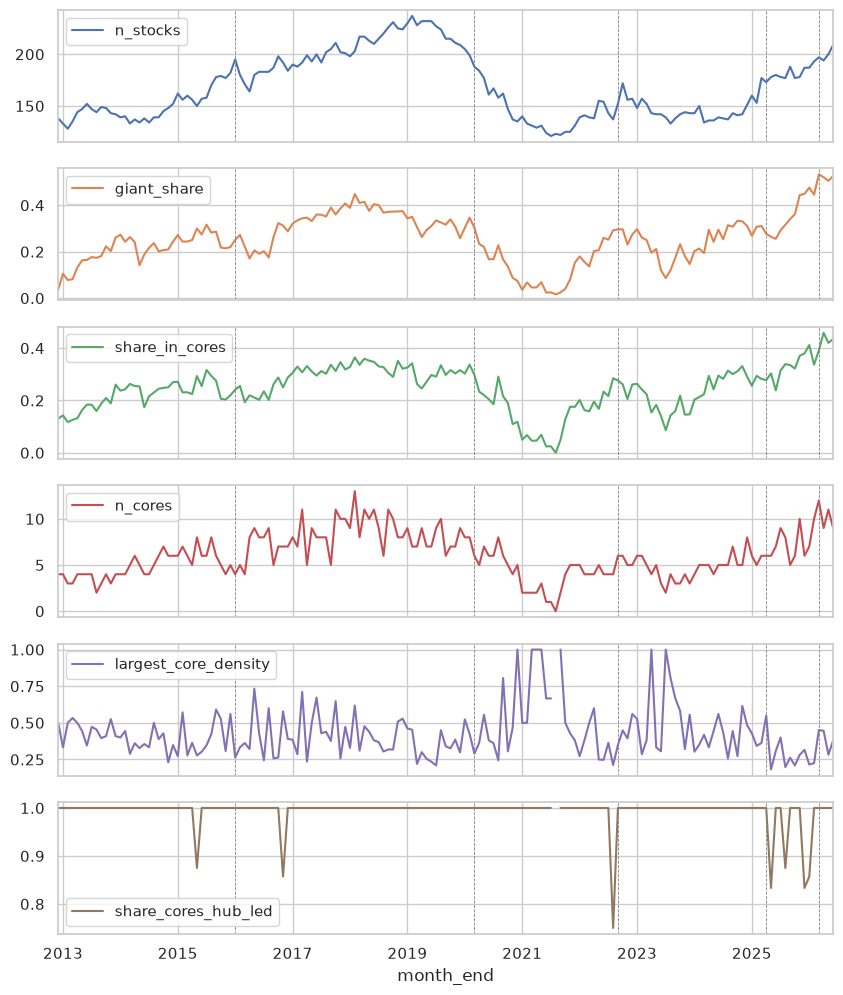

In [28]:
nm = network_df.set_index("month_end")
cols = ["n_stocks", "giant_share", "share_in_cores", "n_cores", "largest_core_density", "share_cores_hub_led"]
ax = nm[cols].plot(subplots=True, figsize=(10, 12), sharex=True)
for a in ax:
    for d in ["2016-01-31", "2020-03-31", "2022-09-30", "2025-04-30", "2026-03-31"]:
        a.axvline(pd.Timestamp(d), ls="--", lw=0.6, c="grey")

agg_short  n_holders     n_eff  overlap_deg  hub_exposure
25%         0.803043  0.778828     0.559716      0.191488
50%         0.839671  0.811998     0.625595      0.265405
75%         0.864722  0.841182     0.695039      0.337376


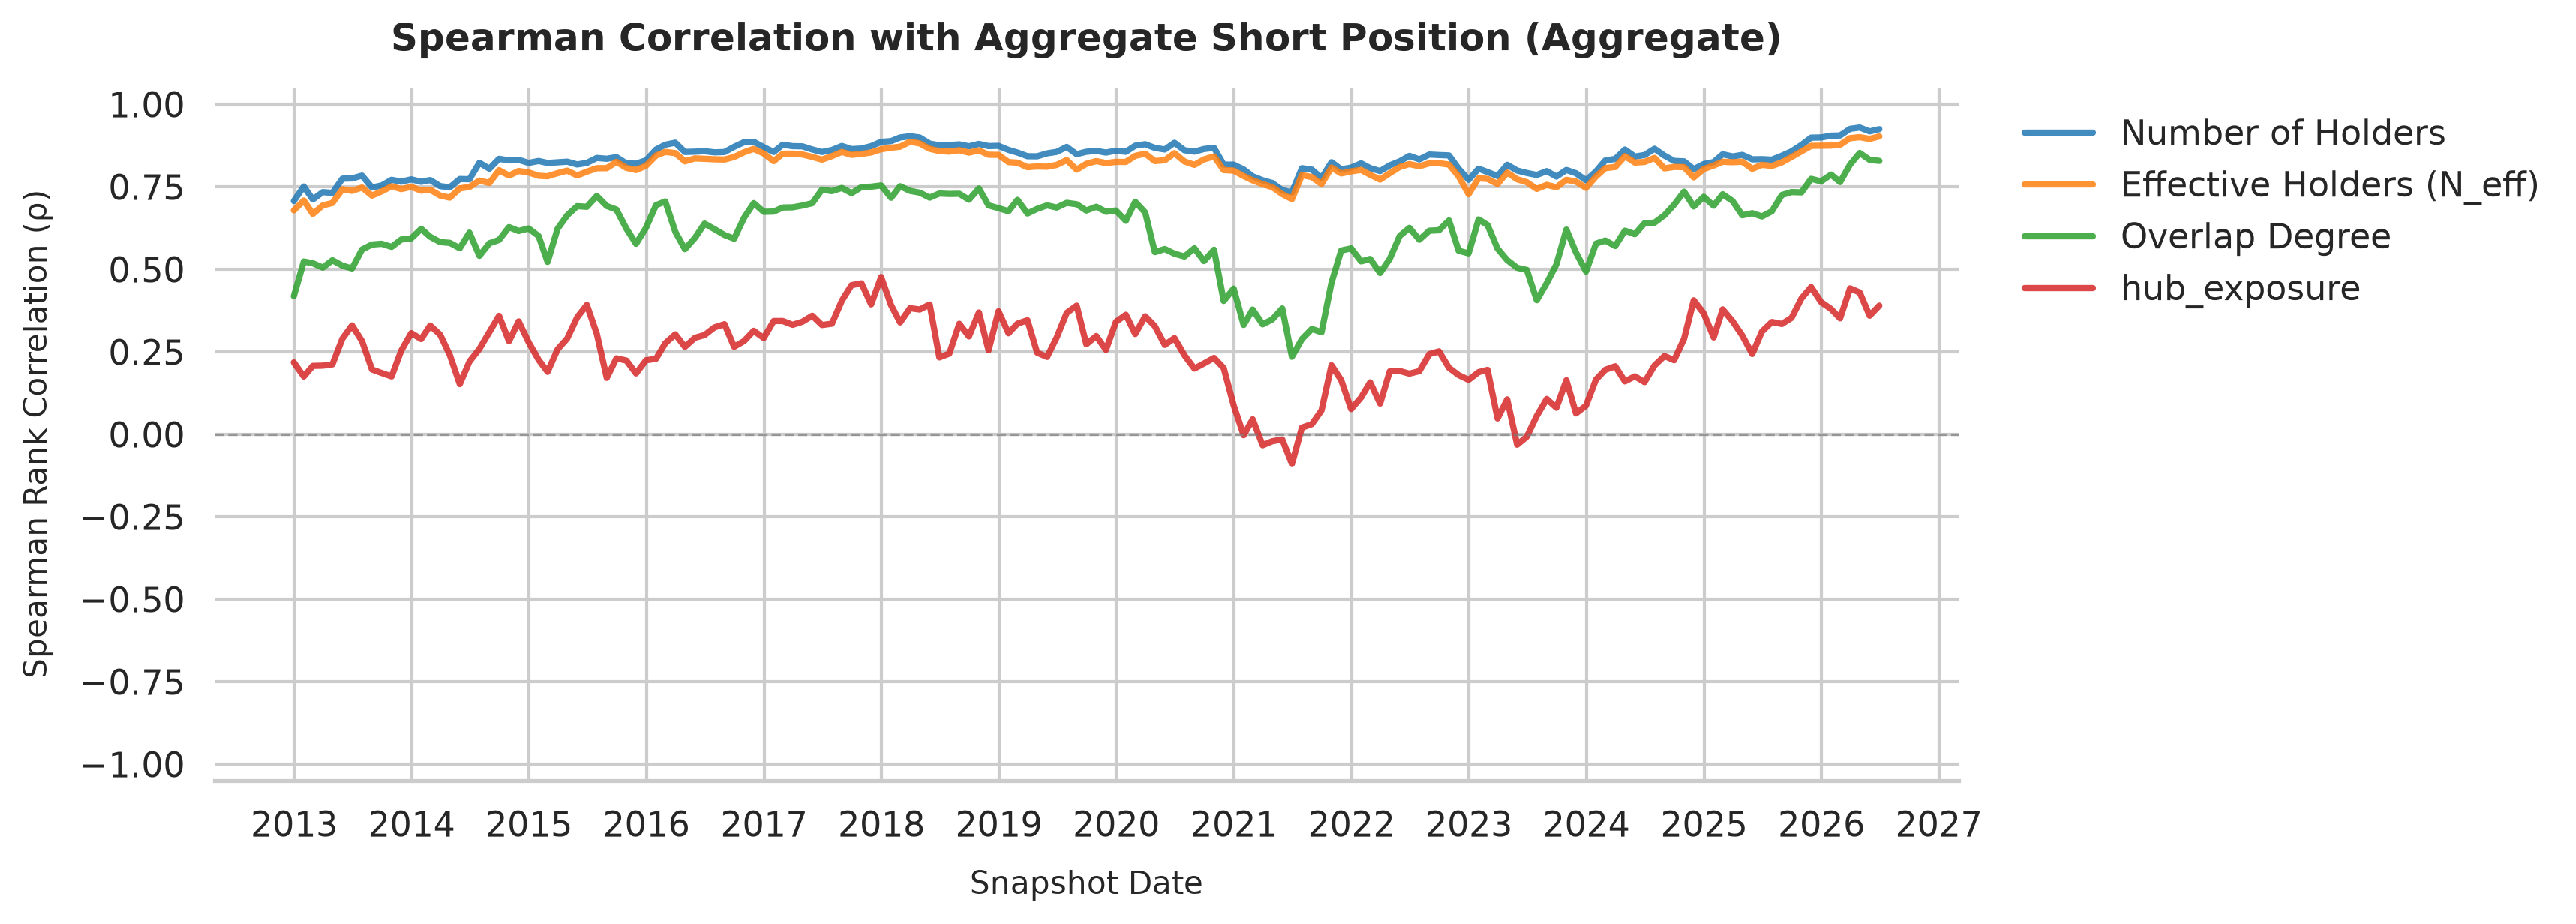

In [29]:
m = ["agg_short", "n_holders", "n_eff", "overlap_deg", "hub_exposure"]
rho = agg_crowding_df.groupby("month_end").apply(lambda g: g[m].corr("spearman").loc["agg_short"])
print(rho.drop(columns="agg_short").describe().loc[["25%", "50%", "75%"]])
# rho.drop(columns="agg_short").plot(figsize=(10, 4))

rho = agg_crowding_df.groupby("month_end").apply(
        lambda g: g[["agg_short", "n_holders", "n_eff", "overlap_deg", "hub_exposure"]]
        .corr("spearman")
        .loc["agg_short"],
        include_groups=False,
    )
rho_clean = rho.drop(columns=["agg_short"])

rho_long = rho_clean.reset_index().melt(
    id_vars="month_end", var_name="metric", value_name="spearman_rho"
)
metric_labels = {
    "n_holders": "Number of Holders",
    "n_eff": "Effective Holders (N_eff)",
    "overlap_deg": "Overlap Degree",
}
rho_long["metric"] = rho_long["metric"].replace(metric_labels)

sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(10, 4), dpi=300)

palette = sns.color_palette("tab10", n_colors=rho_long["metric"].nunique())

# style="metric" uses solid, dashed, and dotted lines so overlapping curves show through
sns.lineplot(
    data=rho_long,
    x="month_end",
    y="spearman_rho",
    hue="metric",
    palette=palette,
    linewidth=2.0,
    alpha=0.85,
    ax=ax,
)

ax.axhline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)

metric_type = "aggregate"  # or whatever your category string is

ax.set_title(
    f"Spearman Correlation with Aggregate Short Position ({metric_type.capitalize()})",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Snapshot Date", fontsize=10, labelpad=8)
ax.set_ylabel("Spearman Rank Correlation (ρ)", fontsize=10, labelpad=8)
ax.set_ylim(-1.05, 1.05)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))

sns.despine(left=True, bottom=False)

ax.legend(
    title="",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

plt.show()
out_dir = "../reports/figures"
os.makedirs(out_dir, exist_ok=True)
fig.savefig(
    os.path.join(out_dir, f"correlation_over_time_{type}.png"),
    bbox_inches="tight",
    dpi=300,
)
plt.close(fig)

In [30]:
life = core_summary_df.groupby("core_track_id").agg(
    months=("month_end", "nunique"), start=("month_end", "min"), end=("month_end", "max"),
    med_size=("size", "median"), hub_led_share=("hub_led", "mean"), med_coassign=("coassign", "median"))
print(life.months.describe())
print((life.months >= 3).mean(), (life.months >= 12).mean())

count    679.000000
mean       1.438881
std        1.188200
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       19.000000
Name: months, dtype: float64
0.09278350515463918 0.0014727540500736377


In [31]:
c = core_df[core_df.core_id >= 0].merge(panel_df[["month_end", "ISIN", "pos_holder"]], on=["month_end", "ISIN"])
cov = c.groupby(["month_end", "core_track_id", "pos_holder"]).ISIN.nunique().reset_index(name="n")
top = cov.sort_values("n").groupby(["month_end", "core_track_id"]).tail(1)
stab = top.groupby("core_track_id").agg(
    n_distinct_hubs=("pos_holder", "nunique"),
    modal_hub_share=("pos_holder", lambda s: s.value_counts(normalize=True).iloc[0]))
life = life.join(stab)

In [32]:
life = life.join(top.groupby("core_track_id").pos_holder.agg(lambda s: s.value_counts().index[0]).rename("modal_hub"))

count    679.000000
mean       1.438881
std        1.188200
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       19.000000
Name: months, dtype: float64
Mean life of share of groups lasting atleast 3 months: 0.09278350515463918,
Mean life of share of groups lasting atleast 12 months: 0.0014727540500736377
Median life of share of groups lasting atleast 3 months: 0.0,
Median life of share of groups lasting atleast 12 months: 0.0


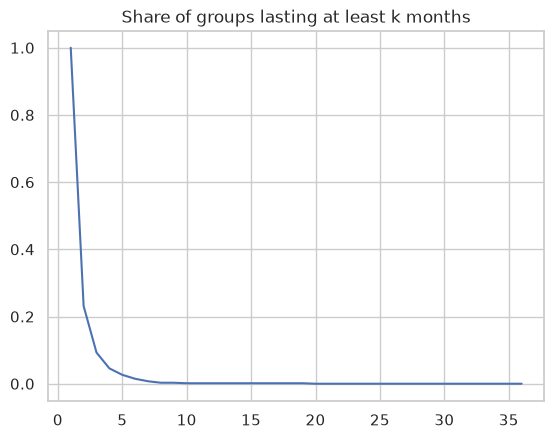

In [33]:
last, first = core_summary_df.month_end.max(), core_summary_df.month_end.min()
life["censored"] = (life.end == last) | (life.start == first)
print(life.months.describe())
surv = [(life.months >= k).mean() for k in range(1, 37)]
pd.Series(surv, index=range(1, 37)).plot(title="Share of groups lasting at least k months")
print(f"Mean life of share of groups lasting atleast 3 months: {(life.months >= 3).mean()},\nMean life of share of groups lasting atleast 12 months: {(life.months >= 12).mean()}")
print(f"Median life of share of groups lasting atleast 3 months: {(life.months >= 3).median()},\nMedian life of share of groups lasting atleast 12 months: {(life.months >= 12).median()}")

In [34]:
life["life_bin"] = pd.cut(life.months, [0, 2, 5, 11, 999], labels=["1–2", "3–5", "6–11", "12+"])
print(life.groupby("life_bin", observed=True)[["med_size", "med_coassign", "hub_led_share", "modal_hub_share"]].median())

          med_size  med_coassign  hub_led_share  modal_hub_share
life_bin                                                        
1–2            6.0      0.986667            1.0         1.000000
3–5            6.0      1.000000            1.0         0.800000
6–11           5.0      1.000000            1.0         0.833333
12+            9.0      1.000000            1.0         0.789474


In [35]:
pers = life[life.months >= 3].copy()
pers["type"] = np.select(
    [(pers.modal_hub_share >= 0.8) & (pers.hub_led_share >= 0.5), pers.hub_led_share >= 0.5],
    ["single_anchor", "rotating_hub"], default="multi_fund")
print(pers.type.value_counts(normalize=True))

type
single_anchor    0.52381
rotating_hub     0.47619
Name: proportion, dtype: float64


In [36]:
anchors = pers.groupby("modal_hub").agg(n_tracks=("months", "size"), track_months=("months", "sum"))
print(anchors.sort_values("track_months", ascending=False).head(10))
print(anchors.track_months.nlargest(5).sum() / anchors.track_months.sum())

                                      n_tracks  track_months
modal_hub                                                   
blackrock_investment_management             14            75
glg_partners                                 9            31
jpmorgan_asset_management                    6            22
lansdowne_partners                           3            16
marshall_wace                                4            15
aqr_capital_management                       4            13
jupiter_investment_management                3            13
ennismore_fund_management                    2             9
canada_pension_plan_investment_board         1             7
lone_pine_capital                            1             7
0.5955056179775281


In [37]:
active = core_summary_df[core_summary_df.core_track_id.isin(pers.index)].groupby("month_end").core_track_id.nunique()
ends = pers[~pers.censored].groupby("end").size()

In [38]:
# print(CONFIG["hub_coverage"])
last = core_summary_df[core_summary_df.month_end == core_summary_df.month_end.max()]
print(last[["size", "n_funds", "top1_cov", "top2_cov", "hub_led"]])

     size  n_funds  top1_cov  top2_cov  hub_led
968    21       31  0.761905  0.476190     True
969    20       30  0.700000  0.450000     True
970    14       26  0.928571  0.785714     True
971     9       17  0.777778  0.555556     True
972     7       12  0.857143  0.428571     True
973     6       10  1.000000  1.000000     True
974     6        9  1.000000  1.000000     True
975     4       11  0.750000  0.750000     True
976     4       16  1.000000  0.750000     True
